<img src=https://audiovisuales.icesi.edu.co/assets/custom/images/ICESI_logo_prin_descriptor_RGB_POSITIVO_0924.jpg width=200>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juanestebancg2806/ml3-time-series-forecasting/blob/main/sesion-02-regresion-tendencia-estacionalidad/ejercicio2_pronostico_ocupados_regresion.ipynb)

# Pronóstico del número de ocupados en las 13 principales ciudades de Colombia con regresión lineal

**Aprendizaje Automático III — Universidad Icesi**

**Integrantes:** Juan Esteban Cardona, Daniel Velasco

Este notebook construye y evalúa modelos de regresión lineal para pronosticar el número mensual de ocupados, en miles de personas, de las 13 principales ciudades de Colombia en los próximos 6 meses. Los modelos representan la serie como una función del tiempo, con distintas formas de modelar su tendencia y su estacionalidad. Los modelos se eligen con una validación que respeta el orden temporal de los datos, se revisan los supuestos de los residuales del modelo elegido y su desempeño se evalúa en una muestra de prueba con los 6 meses más recientes, que no se usa para tomar ninguna decisión de modelado. Finalmente, el modelo se ajusta con toda la serie para pronosticar de julio a diciembre de 2019.

## 1. Carga de paquetes

El notebook se desarrolló con Python 3.13 y las versiones de las librerías que se instalan en la celda siguiente. En un entorno que ya las tenga no hace falta instalarlas; en Google Colab, la celda de instalación se descomenta y se reinicia la sesión antes de continuar.

Después de cargar los paquetes se imprimen las versiones del entorno. A diferencia de los modelos que se estiman con un optimizador numérico, la regresión por mínimos cuadrados tiene una solución cerrada, por lo que los coeficientes y los errores deberían coincidir entre sistemas operativos o procesadores, salvo diferencias en los últimos decimales.

In [1]:
# Instalación de las librerías con las versiones usadas en este notebook.
# Solo es necesaria en Google Colab o en un entorno que no las tenga instaladas:
# quitar el comentario de la línea %pip y, en Colab, reiniciar la sesión después
# de instalar (Entorno de ejecución > Reiniciar sesión) para que se carguen las
# versiones nuevas. Requiere Python 3.12 o superior.

# %pip install pandas==3.1.1 numpy==2.5.4 matplotlib==3.11.2 statsmodels==0.15.0 scikit-learn==1.9.1 scipy==1.18.1 openpyxl==3.1.5

In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.model_selection import TimeSeriesSplit   # validación con origen móvil
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
from statsmodels.tsa.seasonal import seasonal_decompose   # descomposición (solo para describir la serie)
import statsmodels.api as sm   # regresión lineal por MCO

In [3]:
# Versiones del entorno de ejecución, para poder reproducir los resultados
import platform
import sys

import matplotlib
import openpyxl
import scipy
import sklearn
import statsmodels

print(f"{'Python':<14}{sys.version.split()[0]}")
print(f"{'Plataforma':<14}{platform.platform()}")
for nombre_libreria, modulo in [
    ("pandas", pd),
    ("numpy", np),
    ("matplotlib", matplotlib),
    ("statsmodels", statsmodels),
    ("scikit-learn", sklearn),
    ("scipy", scipy),
    ("openpyxl", openpyxl),
]:
    print(f"{nombre_libreria:<14}{modulo.__version__}")

Python        3.13.9
Plataforma    macOS-27.0.1-arm64-arm-64bit-Mach-O
pandas        3.1.1
numpy         2.5.4
matplotlib    3.11.2
statsmodels   0.15.0
scikit-learn  1.9.1
scipy         1.18.1
openpyxl      3.1.5


## 2. Carga y exploración de los datos

Los datos provienen del archivo `datosEmpleo.xlsx`, que contiene series mensuales del mercado laboral de las 13 principales ciudades de Colombia. Para este ejercicio se usa la columna `Ocupados`, que corresponde al número de ocupados en miles de personas. Antes de construir los modelos se revisa el periodo cubierto, si hay valores faltantes y la forma de la serie, porque de ella depende cómo se representan la tendencia y la estacionalidad en la regresión.

Observaciones: 222
Periodo: 2001-01 a 2019-06
Valores faltantes: 0
count      222.0
mean      9160.9
std       1295.5
min       6923.6
25%       7971.1
50%       9139.1
75%      10458.5
max      11037.2
Name: Ocupados, dtype: float64


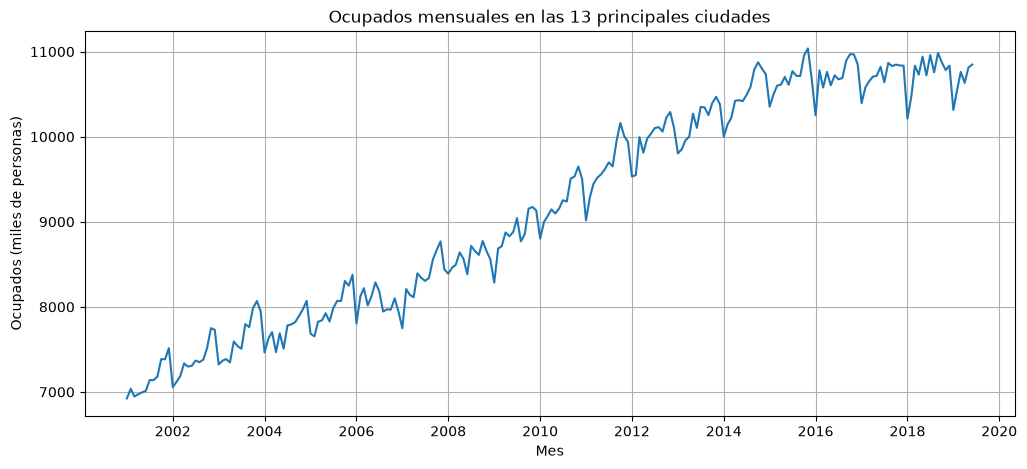

In [4]:
# Carga de datos: la columna "mes" se usa como índice de fechas
data = pd.read_excel(
    "https://raw.githubusercontent.com/dagudelo30/Aprendizaje-automatico-III/main/Clase_1/datosEmpleo.xlsx",
    index_col="mes",
    parse_dates=True,
)

# Serie de ocupados (miles de personas).
# asfreq("MS") declara la frecuencia mensual (inicio de mes): si faltara algún mes,
# aparecería como valor faltante.
ocupados = data["Ocupados"].asfreq("MS")

print("Observaciones:", len(ocupados))
print("Periodo:", ocupados.index.min().strftime("%Y-%m"), "a", ocupados.index.max().strftime("%Y-%m"))
print("Valores faltantes:", ocupados.isna().sum())
print(ocupados.describe().round(1))

# Gráfica de la serie completa
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ocupados)
ax.set_title("Ocupados mensuales en las 13 principales ciudades")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.grid()
plt.show()

### Lectura de la serie

La serie tiene 222 observaciones mensuales, de enero de 2001 a junio de 2019, sin valores faltantes. El número de ocupados va de un mínimo de 6,924 mil personas a un máximo de 11,037 mil, con una media de 9,161 mil.

- **Tendencia:** los ocupados crecen de forma casi lineal entre 2001 y 2015, de cerca de 7 millones a cerca de 10.7 millones, y desde 2016 el crecimiento se detiene y la serie se mantiene entre 10.2 y 11 millones. Esto es importante para la regresión, porque un polinomio del tiempo estima una sola curva para toda la historia: una recta no puede representar el cambio de pendiente, y un polinomio de mayor grado puede seguirlo dentro de la muestra, pero curvarse de forma poco realista al extenderse hacia el futuro.
- **Estacionalidad:** todos los años se repite el mismo patrón. Los ocupados caen con fuerza en enero, se recuperan en los meses siguientes y alcanzan sus valores más altos en el último trimestre. Como el patrón depende solo del mes del año, se puede representar en la regresión con variables que identifiquen el mes.
- **Tamaño de la oscilación:** la caída de enero parece hacerse más profunda a medida que aumenta el nivel de la serie, lo que sugiere un efecto estacional proporcional al nivel y no una cantidad fija de personas.
- **Componente irregular:** además de la tendencia y la estacionalidad, la serie presenta fluctuaciones de un mes a otro sin un patrón claro, que en la regresión corresponden al término de error.

## 3. Partición de entrenamiento y prueba

Como el objetivo es pronosticar los próximos 6 meses, los últimos 6 meses de la serie se reservan como muestra de prueba: de enero a junio de 2019. Así, la evaluación final mide el desempeño de los modelos en el mismo horizonte en el que se usarán. El resto de la serie, de enero de 2001 a diciembre de 2018, forma la muestra de entrenamiento.

La partición respeta el orden temporal: todos los datos de entrenamiento son anteriores a los de prueba. Además, la muestra de prueba no se usa para tomar ninguna decisión de modelado, como el grado de la tendencia o la forma de representar la estacionalidad. Esas decisiones se toman solo con el entrenamiento, para que el error en la prueba sea una estimación honesta del desempeño del modelo con datos que no ha visto.

Entrenamiento: 2001-01 a 2018-12 (216 meses)
Prueba:        2019-01 a 2019-06 (6 meses)


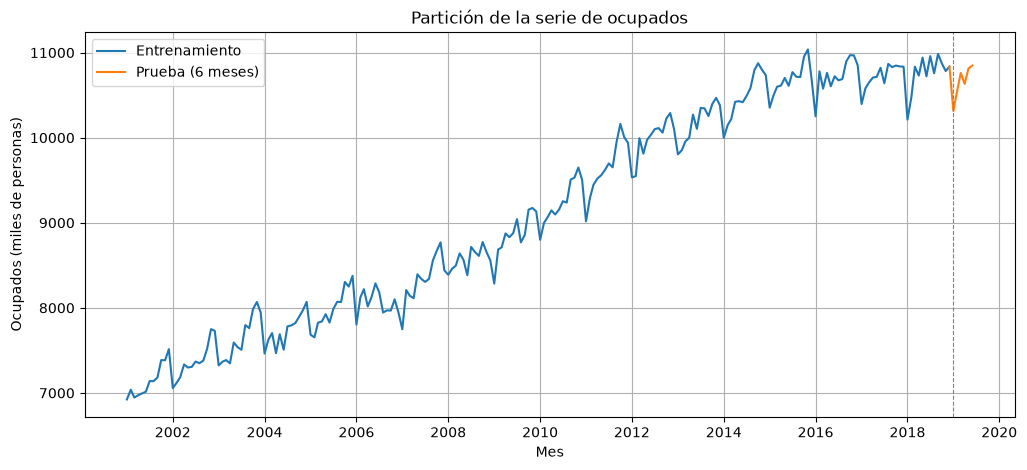

In [5]:
# Horizonte de pronóstico: 6 meses
horizonte = 6

# Partición temporal: los últimos 6 meses se reservan como prueba
train = ocupados.iloc[:-horizonte]
test = ocupados.iloc[-horizonte:]

print("Entrenamiento:", train.index.min().strftime("%Y-%m"), "a", train.index.max().strftime("%Y-%m"), f"({len(train)} meses)")
print("Prueba:       ", test.index.min().strftime("%Y-%m"), "a", test.index.max().strftime("%Y-%m"), f"({len(test)} meses)")

# Gráfica de la partición. La línea de prueba se dibuja desde el último mes de
# entrenamiento solo para que la gráfica se vea continua; los datos no cambian.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train, label="Entrenamiento")
ax.plot(pd.concat([train.iloc[-1:], test]), label="Prueba (6 meses)", color="C1")
ax.axvline(test.index[0], color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Partición de la serie de ocupados")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend()
ax.grid()
plt.show()

La muestra de entrenamiento tiene 216 meses, de enero de 2001 a diciembre de 2018, y la de prueba 6 meses, de enero a junio de 2019. La prueba comienza con la caída estacional de enero y continúa con la recuperación de los meses siguientes, de modo que permite evaluar si los modelos capturan el patrón estacional de la serie y no solo su nivel.

## 4. Componentes de la serie y tipo de estacionalidad

Antes de definir los regresores, la serie de entrenamiento se descompone en tendencia, estacionalidad y residuo. La descomposición no se usa para pronosticar, sino para orientar tres decisiones de la regresión: qué forma debe tener la tendencia, cómo representar el patrón estacional y si el efecto de cada mes es una cantidad fija de personas (estacionalidad aditiva) o un porcentaje del nivel de la serie (estacionalidad multiplicativa).

La última decisión es importante porque una regresión lineal solo suma sus componentes. Si la estacionalidad es multiplicativa, $y_t = T_t \cdot S_t \cdot R_t$, la regresión se ajusta sobre el logaritmo de la serie, donde los componentes se suman: $\log y_t = \log T_t + \log S_t + \log R_t$. Se descompone solo el entrenamiento, para que estas decisiones no dependan de la muestra de prueba.

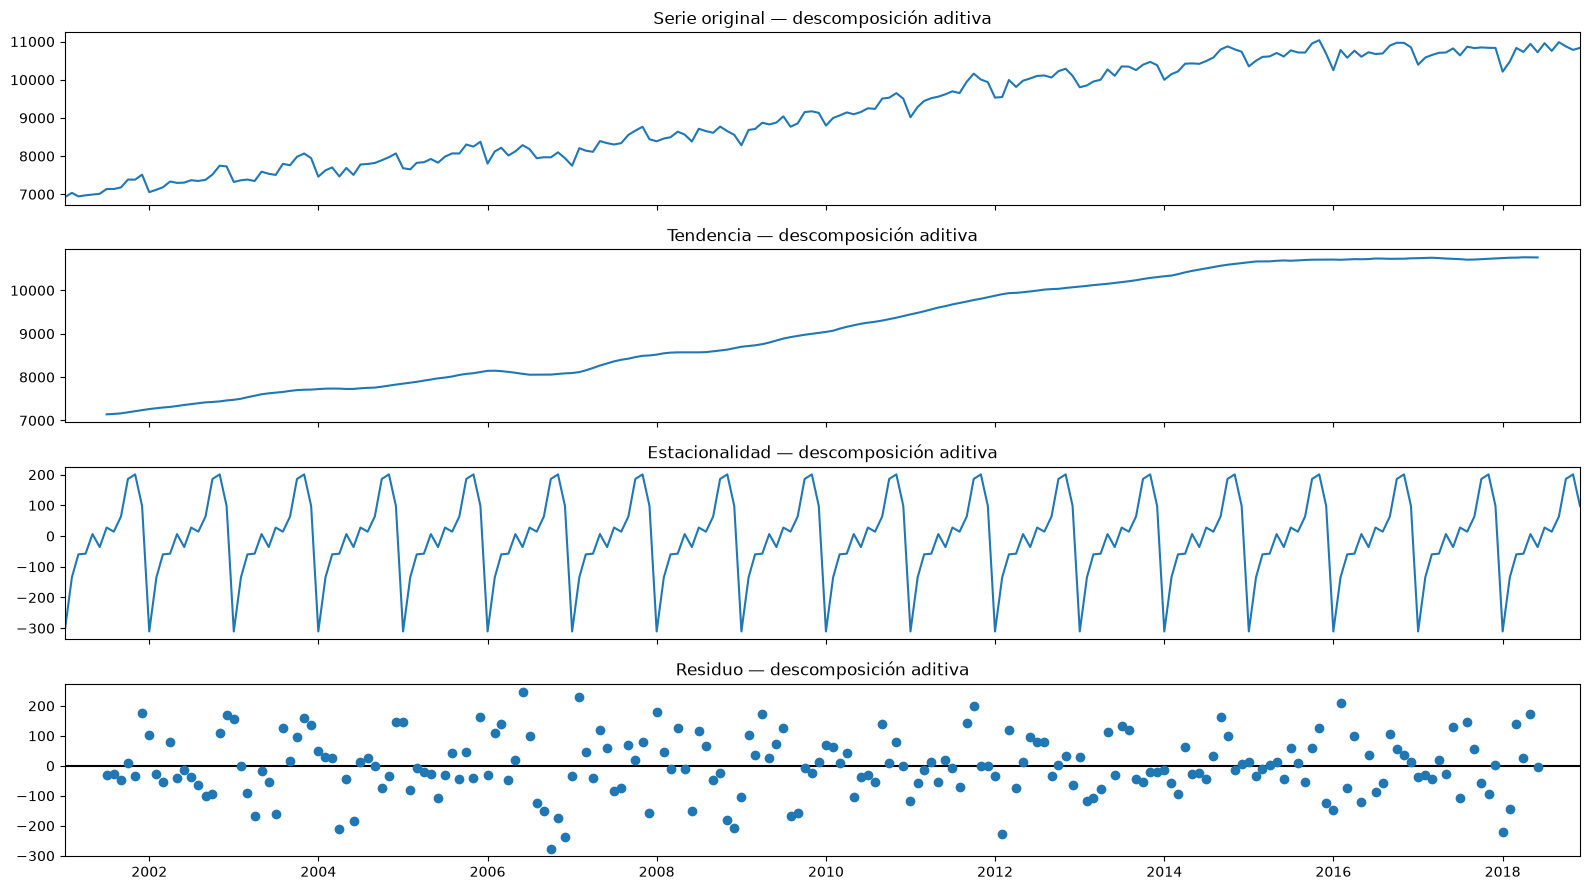

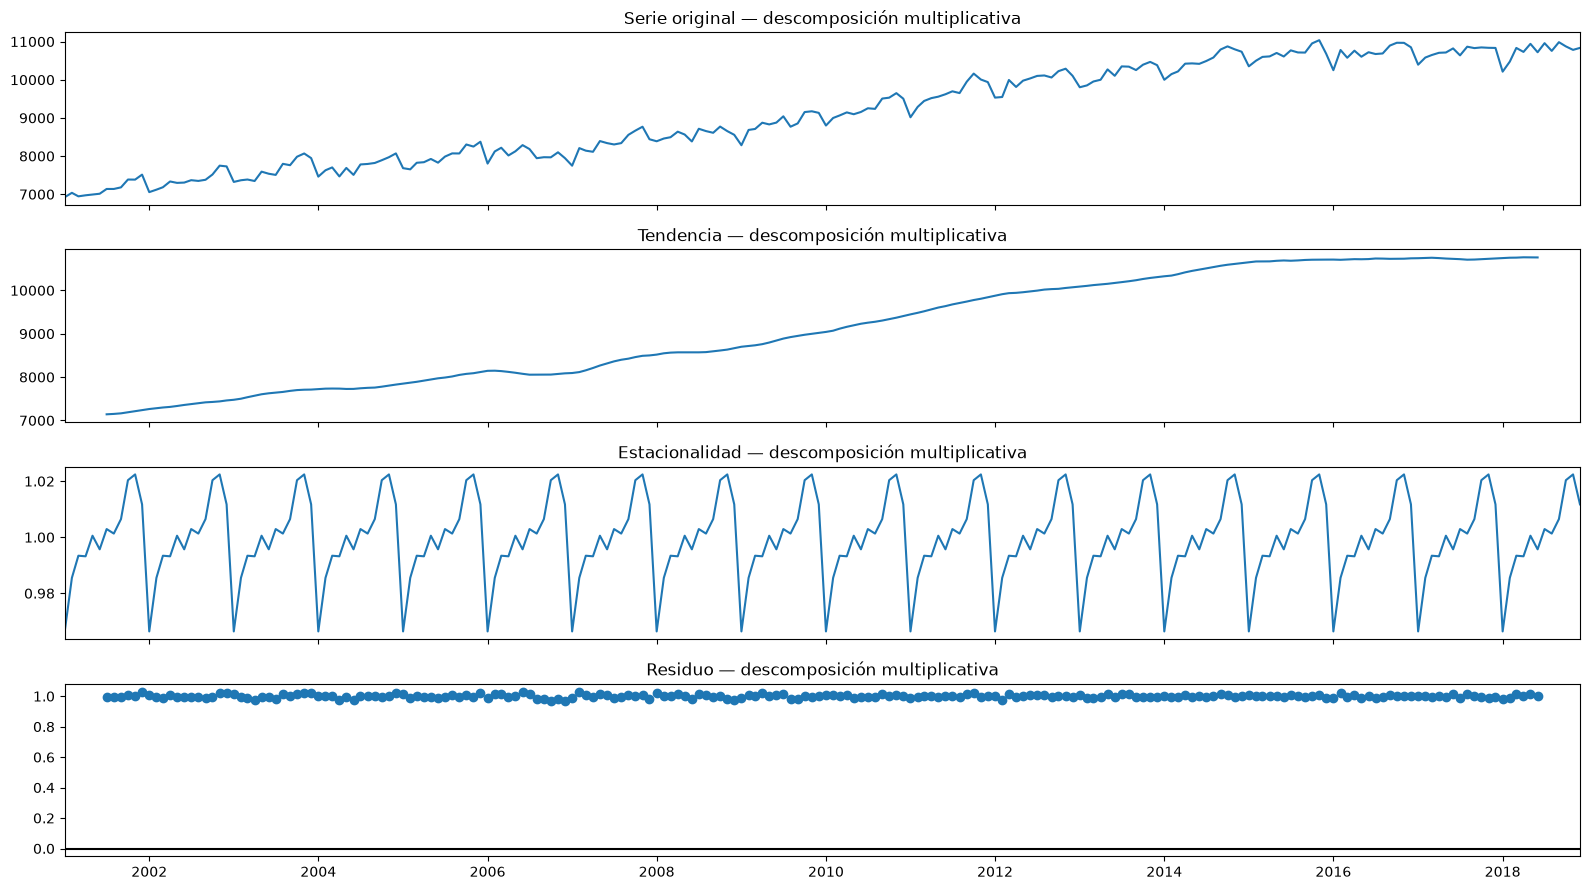

     Aditivo (miles de personas)  Multiplicativo (factor)
Ene                     -310.479                    0.966
Feb                     -134.241                    0.986
Mar                      -59.495                    0.993
Abr                      -57.295                    0.993
May                        6.527                    1.001
Jun                      -35.769                    0.996
Jul                       27.708                    1.003
Ago                       14.336                    1.001
Sep                       63.805                    1.006
Oct                      185.986                    1.020
Nov                      200.802                    1.022
Dic                       98.116                    1.012


In [6]:
# Descomposición clásica del entrenamiento con ambos supuestos
desc_aditiva = seasonal_decompose(train, model="additive")
desc_multiplicativa = seasonal_decompose(train, model="multiplicative")

# Gráficas de ambas descomposiciones, con títulos en español
titulos = ["Serie original", "Tendencia", "Estacionalidad", "Residuo"]
for desc, nombre in [(desc_aditiva, "aditiva"), (desc_multiplicativa, "multiplicativa")]:
    fig = desc.plot()
    fig.set_size_inches((16, 9))
    for eje, titulo in zip(fig.axes, titulos):
        eje.set_title(f"{titulo} — descomposición {nombre}")
        eje.set_ylabel("")
    fig.tight_layout()
    plt.show()

# Efecto estacional estimado para cada mes con ambos supuestos
# (el entrenamiento empieza en enero, así que las primeras 12 filas van de enero a diciembre)
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
efectos_estacionales = pd.DataFrame({
    "Aditivo (miles de personas)": desc_aditiva.seasonal.iloc[:12].values,
    "Multiplicativo (factor)": desc_multiplicativa.seasonal.iloc[:12].values,
}, index=nombres_meses)
print(efectos_estacionales.round(3))

### Componentes de la serie de entrenamiento

Las dos figuras muestran la descomposición de la serie de entrenamiento con cada supuesto. Cada una tiene cuatro paneles: la serie original, la tendencia, la estacionalidad y el residuo. Bajo el supuesto aditivo, la serie es la suma de las tres piezas (tendencia + estacionalidad + residuo); bajo el multiplicativo, es su producto (tendencia × estacionalidad × residuo).

**Tendencia.** Ambas descomposiciones estiman la misma tendencia, porque las dos la calculan con el mismo promedio móvil centrado de 12 meses. Por esa misma razón, la tendencia no está disponible en los primeros ni en los últimos 6 meses del entrenamiento. Los ocupados crecen de cerca de 7,150 mil a mediados de 2001 a cerca de 10,700 mil en 2015, con una breve pausa entre 2006 y 2007, y desde 2015 se mantienen prácticamente estables hasta 2018. Para la regresión, esto significa que una tendencia lineal estimada con toda la historia tendrá una pendiente positiva que no corresponde a los últimos años, y que un polinomio de mayor grado puede aproximar el aplanamiento, pero también puede extenderlo hacia una caída o una subida que los datos no muestran.

**Estacionalidad.** Ambas descomposiciones encuentran el mismo patrón, repetido de forma idéntica todos los años:

| Mes | Efecto aditivo (miles de personas) | Efecto multiplicativo |
|---|---|---|
| Enero | -310 | 0.966 (3.4 % por debajo de la tendencia) |
| Febrero | -134 | 0.986 (1.4 % por debajo) |
| Octubre | +186 | 1.020 (2.0 % por encima) |
| Noviembre | +201 | 1.022 (2.2 % por encima) |
| Diciembre | +98 | 1.012 (1.2 % por encima) |

Los ocupados caen con fuerza en enero, se recuperan gradualmente entre febrero y abril, se mantienen cerca de la tendencia a mitad de año y alcanzan sus valores más altos en octubre y noviembre. El patrón no es una onda suave: entre diciembre y enero el efecto pasa de +98 a -310 mil personas, un cambio de 408 mil en un solo mes, mientras que entre mayo y septiembre los efectos varían poco. Esta forma es relevante para elegir cómo representar la estacionalidad en la regresión, porque un cambio tan brusco requiere un regresor que permita a cada mes tener su propio efecto, o una combinación de varias ondas de distinta frecuencia.

En el supuesto aditivo, el efecto es una cantidad fija de personas que se suma a la tendencia. En el multiplicativo, es un factor que multiplica la tendencia, por lo que el efecto en personas crece con el nivel de la serie. Por ejemplo, la caída de enero sería de 310 mil personas en cualquier año con el supuesto aditivo, mientras que con el multiplicativo sería de cerca de 245 mil cuando la tendencia está en 7,200 mil y de cerca de 364 mil cuando está en 10,700 mil.

**Residuo.** En la descomposición aditiva, el residuo oscila alrededor de 0, casi siempre entre -250 y 250 mil personas, sin una forma que se repita a simple vista, aunque con algunos valores más alejados entre 2006 y 2007, que coinciden con la pausa de la tendencia. En la descomposición multiplicativa, el residuo no puede evaluarse en la gráfica: la función dibuja la línea de referencia en 0, aunque este residuo gira alrededor de 1, así que los valores quedan comprimidos en una franja casi plana. Además, un patrón que afecte solo a un mes puede quedar escondido entre los demás. Por eso, en la siguiente celda se comparan los residuos de enero, el mes con el mayor efecto estacional, con ambos supuestos y en las mismas unidades.

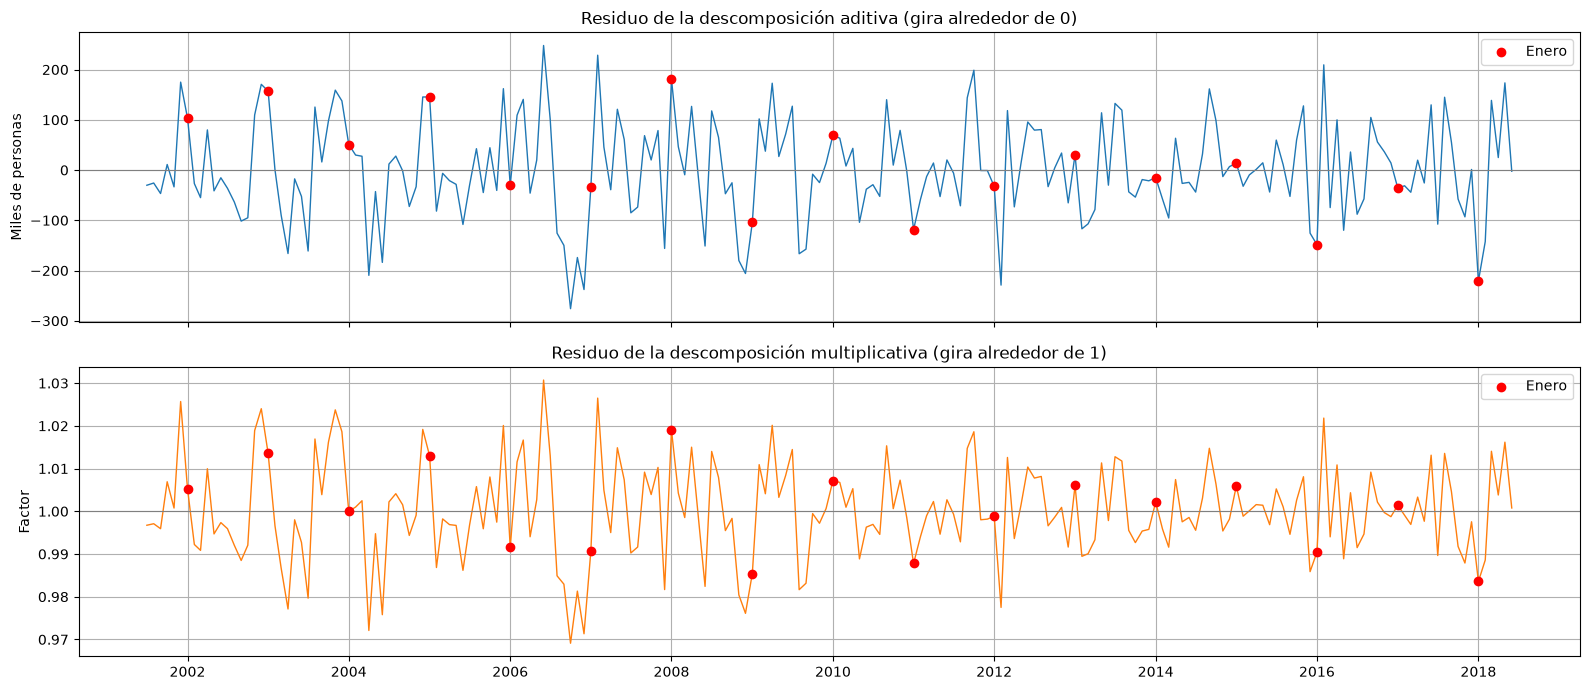

            Tendencia  Residuo aditivo  Residuo multiplicativo  Caída real (miles)  Caída real (%)  Residuo multiplicativo (miles)
mes                                                                                                                               
2002-01-01   7263.377          103.436                   1.005             207.043           2.851                          36.974
2003-01-01   7476.767          157.169                   1.014             153.310           2.050                          97.876
2004-01-01   7722.007           50.852                   1.000             259.627           3.362                          -0.202
2005-01-01   7849.145          145.386                   1.013             165.093           2.103                          98.603
2006-01-01   8144.433          -29.839                   0.992             340.318           4.179                         -66.702
2007-01-01   8093.627          -34.342                   0.991             344.821 

In [7]:
# Comparación de los residuos de enero, el mes con el mayor efecto estacional.
# Si el supuesto es correcto, estos residuos no deben quedar sistemáticamente
# arriba o abajo de la referencia en algún periodo.
es_enero = train.index.month == 1

# Gráfica de ambos residuos en su propia escala, con los eneros resaltados
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)

axes[0].plot(desc_aditiva.resid, color="C0", linewidth=1)
axes[0].scatter(train.index[es_enero], desc_aditiva.resid[es_enero], color="red", zorder=3, label="Enero")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_title("Residuo de la descomposición aditiva (gira alrededor de 0)")
axes[0].set_ylabel("Miles de personas")
axes[0].legend()
axes[0].grid()

axes[1].plot(desc_multiplicativa.resid, color="C1", linewidth=1)
axes[1].scatter(train.index[es_enero], desc_multiplicativa.resid[es_enero], color="red", zorder=3, label="Enero")
axes[1].axhline(1, color="gray", linewidth=0.8)
axes[1].set_title("Residuo de la descomposición multiplicativa (gira alrededor de 1)")
axes[1].set_ylabel("Factor")
axes[1].legend()
axes[1].grid()

fig.tight_layout()
plt.show()

# Tendencia, residuos y caída real de cada enero.
# La caída real es cuánto quedó enero por debajo de la tendencia en ese año.
eneros = pd.DataFrame({
    "Tendencia": desc_aditiva.trend[es_enero],
    "Residuo aditivo": desc_aditiva.resid[es_enero],
    "Residuo multiplicativo": desc_multiplicativa.resid[es_enero],
})
eneros["Caída real (miles)"] = eneros["Tendencia"] - train[es_enero]
eneros["Caída real (%)"] = 100 * eneros["Caída real (miles)"] / eneros["Tendencia"]

# Residuo multiplicativo expresado en miles para compararlo con el aditivo.
# En el modelo multiplicativo Y = T * S * R, el desvío en miles es T * S * (R - 1).
factor_enero = desc_multiplicativa.seasonal[es_enero]
eneros["Residuo multiplicativo (miles)"] = (
    eneros["Tendencia"] * factor_enero * (eneros["Residuo multiplicativo"] - 1)
)

# Enero de 2001 no tiene tendencia (el promedio móvil centrado pierde los primeros 6 meses)
eneros = eneros.dropna()
print(eneros.round(3).to_string())

comparacion_residuos = eneros[["Residuo aditivo", "Residuo multiplicativo (miles)"]]
print("\nPromedio del valor absoluto del residuo de enero (miles):")
print(comparacion_residuos.abs().mean().round(1).to_string())

print("\nPromedio del residuo de enero por periodo (miles):")
print(pd.DataFrame({
    "2002-2005": comparacion_residuos.loc["2002":"2005"].mean(),
    "2016-2018": comparacion_residuos.loc["2016":"2018"].mean(),
}).round(1).to_string())

### Elección del tipo de estacionalidad

Para decidir entre el supuesto aditivo y el multiplicativo se analizaron los eneros, porque enero es el mes con el mayor efecto estacional: la descomposición aditiva estima una caída fija de 310.5 mil personas frente a la tendencia, y la multiplicativa una caída de 3.4 % (factor de 0.966). Si el supuesto es correcto, los residuos de enero deberían oscilar alrededor de cero sin un patrón en el tiempo. Como los dos residuos están en unidades distintas, el multiplicativo se expresó en miles como $T_t \cdot S_t \cdot (R_t - 1)$, es decir, el valor esperado por el modelo multiplicado por el porcentaje en que se aleja de él.

| Residuo de enero (miles) | Aditivo | Multiplicativo |
|---|---|---|
| Promedio del valor absoluto, 2002-2018 | 87.7 | 74.3 |
| Promedio 2002-2005 | +114.2 | +58.3 |
| Promedio 2016-2018 | -135.0 | -85.0 |

Con el supuesto aditivo hay un sesgo claro. Entre 2002 y 2005, cuando la tendencia estaba entre 7,263 y 7,849 mil, la caída real de enero fue de 153 a 260 mil personas, menor que la estimada, y el residuo queda positivo. En 2016 y 2018, con una tendencia cercana a 10,700 mil, la caída real fue de 459 y 532 mil, mayor que la estimada, y el residuo queda negativo. Es decir, la caída de enero creció con el nivel de la serie, lo que contradice el supuesto aditivo de un efecto fijo en personas. El supuesto multiplicativo reduce este sesgo: el error promedio baja de 87.7 a 74.3 mil (cerca de 15 %) y los promedios por periodo se reducen a +58.3 y -85.0 mil.

El sesgo, sin embargo, no desaparece. La caída de enero como porcentaje de la tendencia varía bastante de un año a otro, entre 1.5 % y 4.9 %, pero en promedio pasó de 2.6 % en 2002-2005 a 4.2 % en 2016-2018, es decir, creció incluso más que en proporción al nivel. Esto sugiere que el patrón estacional cambió con el tiempo. Una regresión con efectos de mes fijos estima un único patrón para todo el periodo de ajuste, igual que la descomposición clásica, de modo que tampoco puede capturar este cambio si se estima con toda la historia.

Por lo tanto, el supuesto multiplicativo describe mejor la serie, pero la ventaja es moderada. En la regresión se evaluarán ambos tipos de estacionalidad: el aditivo ajustando la serie en su escala original y el multiplicativo ajustando su logaritmo. La elección final se hará con el error de pronóstico en la validación.

## 5. Esquema de validación y modelos de referencia

Para elegir entre modelos y configuraciones sin usar la muestra de prueba, se aplica una validación con origen móvil dentro del entrenamiento. Es la versión de la validación cruzada para series de tiempo: en lugar de partir los datos al azar, se definen varios cortes en el tiempo, y en cada uno el modelo se ajusta con los meses anteriores al corte y pronostica los 6 meses siguientes. En la regresión, ajustar significa volver a estimar los coeficientes solo con los datos disponibles hasta el corte, de modo que ningún pronóstico usa información posterior. Se usan 6 cortes, de modo que cada modelo se evalúa en 6 semestres distintos entre 2016 y 2018, y no depende de un solo periodo. En cada corte se calculan dos métricas:

- **RMSE** (raíz del error cuadrático medio), en miles de personas, que penaliza más los errores grandes.
- **MAPE** (error porcentual absoluto medio), en porcentaje del valor real, que permite leer el error en términos relativos.

El criterio principal de selección es el RMSE promedio de los 6 cortes, porque está en las mismas unidades de la serie y castiga con más fuerza los meses en que el pronóstico se aleja mucho del valor real. El MAPE promedio se usa como complemento, y entre los mejores modelos se revisa además en cuántos cortes cada uno supera al naive estacional, para que la elección no dependa de un solo semestre.

Las medidas de ajuste que reporta la regresión, como el $R^2$, no se usan para elegir el modelo, porque se calculan con los mismos datos con los que se estiman los coeficientes. El $R^2$ aumenta siempre que se agrega un regresor, por ejemplo una potencia más alta del tiempo, aunque el modelo pronostique peor fuera de la muestra. Por eso se reportan solo para interpretar el ajuste.

Como referencia se usan dos pronósticos ingenuos. El **naive** repite el último valor observado en los 6 meses, y el **naive estacional** repite el valor del mismo mes del año anterior. Un modelo solo aporta valor si mejora estas referencias.

In [8]:
# Validación con origen móvil dentro del entrenamiento (la muestra de prueba no se usa aquí).
# TimeSeriesSplit no mezcla los datos: cada corte ajusta con los meses anteriores
# y valida con los 6 meses siguientes. Por defecto la ventana de ajuste es expansiva
# (max_train_size=None), es decir, cada corte tiene disponible toda la historia hasta ese punto.
n_cortes = 6
tscv = TimeSeriesSplit(n_splits=n_cortes, test_size=horizonte)

for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    print(
        f"Corte {numero}: ajuste {train.index[idx_ajuste[0]]:%Y-%m} a {train.index[idx_ajuste[-1]]:%Y-%m} "
        f"({len(idx_ajuste)} meses) | validación {train.index[idx_validacion[0]]:%Y-%m} "
        f"a {train.index[idx_validacion[-1]]:%Y-%m}"
    )

Corte 1: ajuste 2001-01 a 2015-12 (180 meses) | validación 2016-01 a 2016-06
Corte 2: ajuste 2001-01 a 2016-06 (186 meses) | validación 2016-07 a 2016-12
Corte 3: ajuste 2001-01 a 2016-12 (192 meses) | validación 2017-01 a 2017-06
Corte 4: ajuste 2001-01 a 2017-06 (198 meses) | validación 2017-07 a 2017-12
Corte 5: ajuste 2001-01 a 2017-12 (204 meses) | validación 2018-01 a 2018-06
Corte 6: ajuste 2001-01 a 2018-06 (210 meses) | validación 2018-07 a 2018-12


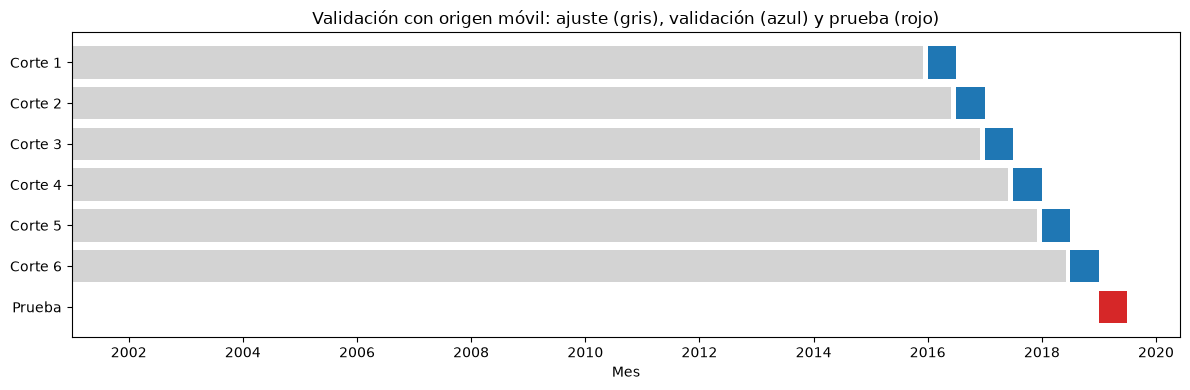

In [9]:
# Diagrama de los cortes de validación y de la muestra de prueba
fig, ax = plt.subplots(figsize=(12, 4))

for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    inicio_ajuste, fin_ajuste = train.index[idx_ajuste[0]], train.index[idx_ajuste[-1]]
    inicio_validacion, fin_validacion = train.index[idx_validacion[0]], train.index[idx_validacion[-1]]
    # Barra gris: meses de ajuste; barra azul: meses de validación
    ax.barh(numero, fin_ajuste - inicio_ajuste, left=inicio_ajuste, color="lightgray")
    ax.barh(numero, fin_validacion - inicio_validacion + pd.Timedelta(days=30),
            left=inicio_validacion, color="C0")

# Muestra de prueba, reservada hasta el final
ax.barh(n_cortes + 1, test.index[-1] - test.index[0] + pd.Timedelta(days=30),
        left=test.index[0], color="C3")

ax.set_yticks(range(1, n_cortes + 2))
ax.set_yticklabels([f"Corte {numero}" for numero in range(1, n_cortes + 1)] + ["Prueba"])
ax.invert_yaxis()
ax.set_title("Validación con origen móvil: ajuste (gris), validación (azul) y prueba (rojo)")
ax.set_xlabel("Mes")
plt.tight_layout()
plt.show()

El diagrama muestra los 6 cortes de la validación. En cada uno, los datos disponibles para ajustar el modelo van desde enero de 2001 hasta el mes anterior al corte (gris), y el modelo se evalúa en los 6 meses siguientes (azul), de modo que los cortes cubren de forma consecutiva los semestres de 2016 a 2018. La muestra de prueba (rojo) queda por fuera de todos los cortes y solo se usa al final, para evaluar el modelo elegido.

In [10]:
def evaluar_validacion(funcion_pronostico, serie=train, cv=tscv):
    """Evalúa un método de pronóstico en cada corte de la validación con origen móvil.

    funcion_pronostico(serie_ajuste, h) debe devolver h pronósticos usando solo serie_ajuste.
    Devuelve una tabla con el RMSE (miles) y el MAPE (%) de cada corte.
    """
    filas = []
    for idx_ajuste, idx_validacion in cv.split(serie):
        serie_ajuste = serie.iloc[idx_ajuste]
        serie_validacion = serie.iloc[idx_validacion]
        pronostico = funcion_pronostico(serie_ajuste, len(serie_validacion))
        filas.append({
            "inicio_validacion": serie_validacion.index[0].strftime("%Y-%m"),
            "rmse": np.sqrt(mean_squared_error(serie_validacion, pronostico)),
            # sklearn devuelve el MAPE como fracción, por eso se multiplica por 100
            "mape": 100 * mean_absolute_percentage_error(serie_validacion, pronostico),
        })
    return pd.DataFrame(filas).set_index("inicio_validacion")


def pronostico_naive(serie_ajuste, h):
    """Repite el último valor observado en los h meses siguientes."""
    return np.repeat(serie_ajuste.iloc[-1], h)


def pronostico_naive_estacional(serie_ajuste, h, m=12):
    """Repite el valor del mismo mes del año anterior (válido para h <= m)."""
    return serie_ajuste.iloc[-m:].iloc[:h].values


# Resultados por corte de cada método; se irán agregando los modelos de regresión a este diccionario
validacion = {}
validacion["Naive"] = evaluar_validacion(pronostico_naive)
validacion["Naive estacional"] = evaluar_validacion(pronostico_naive_estacional)

for nombre, tabla in validacion.items():
    print(f"\n{nombre}")
    print(tabla.round(2))

resumen_validacion = pd.DataFrame({nombre: tabla.mean() for nombre, tabla in validacion.items()}).T
resumen_validacion.columns = ["RMSE promedio", "MAPE promedio (%)"]
print("\nResumen")
print(resumen_validacion.round(2))


Naive
                     rmse  mape
inicio_validacion              
2016-01            191.58  1.33
2016-07            169.33  1.34
2017-01            245.52  1.95
2017-07             77.88  0.45
2018-01            302.74  2.09
2018-07            167.46  1.33

Naive estacional
                     rmse  mape
inicio_validacion              
2016-01            149.37  1.19
2016-07            113.50  0.86
2017-01            122.75  1.07
2017-07            107.29  0.84
2018-01            153.32  1.29
2018-07            153.90  1.02

Resumen
                  RMSE promedio  MAPE promedio (%)
Naive                    192.42               1.41
Naive estacional         133.36               1.05


### Resultados de los modelos de referencia

Los 6 cortes validan semestres consecutivos entre enero de 2016 y diciembre de 2018, con un ajuste que va de 180 a 210 meses, y ninguno usa la muestra de prueba.

| Modelo | RMSE promedio (miles) | MAPE promedio (%) |
|---|---|---|
| Naive | 192.42 | 1.41 |
| Naive estacional | 133.36 | 1.05 |

El naive estacional tiene un RMSE promedio cerca de 31 % menor que el naive. Como entre 2016 y 2018 el nivel de la serie se mantuvo casi constante, la diferencia entre ambos se debe principalmente a que el naive estacional reproduce el patrón del calendario. El naive tiene sus mayores errores en los cortes que empiezan en enero (245.5 mil en 2017 y 302.7 mil en 2018), porque repite en todo el semestre el valor de diciembre, uno de los más altos del año, justo antes de la caída de enero. El error del naive estacional es más estable entre cortes, de 107.3 a 153.9 mil.

El naive estacional se toma como la referencia a superar: un modelo de regresión solo se considera útil si obtiene un RMSE promedio menor a 133.36 mil y un MAPE promedio menor a 1.05 %. Hay que tener en cuenta que esta referencia no incluye tendencia y que en el periodo de validación la tendencia de la serie fue casi plana, lo que la favorece.

## 6. Regresión con tendencia

Un modelo de regresión para series de tiempo explica cada valor de la serie con regresores que dependen solo de la fecha. El más simple usa un polinomio del tiempo como tendencia:

$$y_t = \beta_0 + \beta_1 t + \beta_2 t^2 + \beta_3 t^3 + \varepsilon_t$$

donde $t$ es el tiempo en años desde enero de 2001 ($t = 0$ en enero de 2001, $t = 1/12$ en febrero, y así sucesivamente). Medir el tiempo en años hace que los coeficientes se lean por año y evita que $t^2$ y $t^3$ tomen valores muy grandes. Los coeficientes se estiman por mínimos cuadrados ordinarios (MCO) con los meses de ajuste de cada corte, y el pronóstico se obtiene evaluando la curva estimada en los 6 meses siguientes.

Se evalúan cuatro tendencias: ninguna (solo la constante, es decir, el promedio del periodo de ajuste), lineal, cuadrática y cúbica. En esta sección los modelos todavía no incluyen estacionalidad, para medir primero cuánto aporta la tendencia por sí sola, y en cada corte se usan todos los meses anteriores al corte. Las funciones de esta sección construyen los regresores de forma general, de modo que en las secciones siguientes se reutilizan para agregar la estacionalidad.

Resumen de la validación (ordenado por RMSE)
                  RMSE promedio  MAPE promedio (%)
Naive estacional         133.36               1.05
Naive                    192.42               1.41
Tend. cúbica             262.15               2.15
Tend. lineal             369.80               3.22
Tend. cuadrática         487.08               4.41
Solo constante          1806.82              16.74


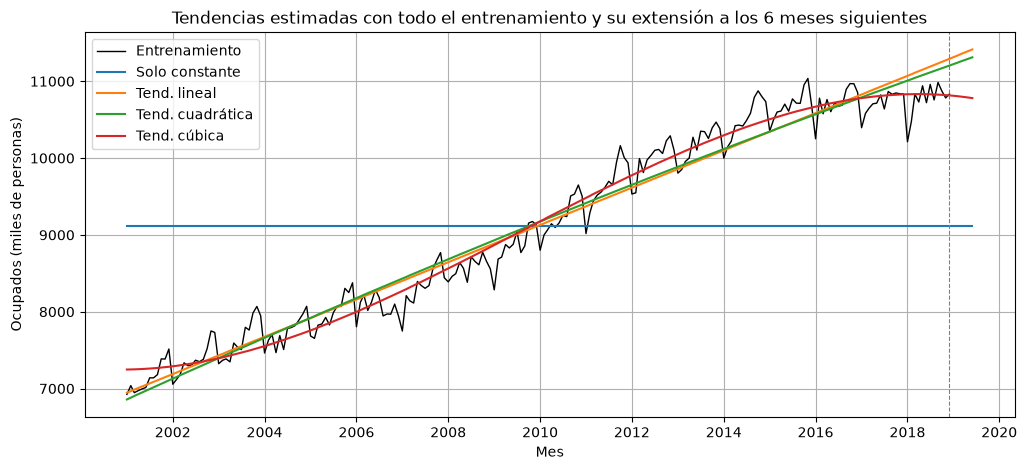


Coeficientes estimados con todo el entrenamiento (t en años):
                     R²     const      t^1     t^2    t^3
Solo constante   -0.000  9119.366      NaN     NaN    NaN
Tend. lineal      0.962  6945.834  242.627     NaN    NaN
Tend. cuadrática  0.963  6858.193  272.114  -1.646    NaN
Tend. cúbica      0.977  7247.538    8.277  35.254 -1.373


In [11]:
# Tiempo de referencia: t = 0 en el primer mes de la serie (enero de 2001)
inicio_serie = ocupados.index[0]


def construir_regresores(fechas, tendencia):
    """Construye la matriz de regresores de la tendencia para las fechas indicadas.

    tendencia: "ninguna", "lineal", "cuadratica" o "cubica" (polinomio en t, medido en años).
    """
    meses_desde_inicio = (fechas.year - inicio_serie.year) * 12 + (fechas.month - inicio_serie.month)
    t = np.asarray(meses_desde_inicio, dtype=float) / 12

    X = pd.DataFrame({"const": np.ones(len(fechas))}, index=fechas)
    grado = {"ninguna": 0, "lineal": 1, "cuadratica": 2, "cubica": 3}[tendencia]
    for potencia in range(1, grado + 1):
        X[f"t^{potencia}"] = t ** potencia
    return X


def fechas_siguientes(serie_ajuste, h):
    """Devuelve las h fechas mensuales posteriores al último mes de serie_ajuste."""
    return pd.date_range(serie_ajuste.index[-1] + pd.DateOffset(months=1), periods=h, freq="MS")


def ajustar_regresion(serie_ajuste, config):
    """Estima por MCO la regresión con la configuración indicada."""
    X = construir_regresores(serie_ajuste.index, config["tendencia"])
    return sm.OLS(serie_ajuste, X).fit()


def pronostico_regresion(serie_ajuste, h, config):
    """Ajusta la regresión con serie_ajuste y pronostica los h meses siguientes."""
    ajuste = ajustar_regresion(serie_ajuste, config)
    X_futuro = construir_regresores(fechas_siguientes(serie_ajuste, h), config["tendencia"])
    return np.asarray(ajuste.predict(X_futuro))


# Configuraciones con tendencia y sin estacionalidad
configuraciones_tendencia = {
    "Solo constante":   dict(tendencia="ninguna"),
    "Tend. lineal":     dict(tendencia="lineal"),
    "Tend. cuadrática": dict(tendencia="cuadratica"),
    "Tend. cúbica":     dict(tendencia="cubica"),
}

for nombre, config in configuraciones_tendencia.items():
    validacion[nombre] = evaluar_validacion(
        lambda serie_ajuste, h, config=config: pronostico_regresion(serie_ajuste, h, config)
    )

resumen_validacion = pd.DataFrame({nombre: tabla.mean() for nombre, tabla in validacion.items()}).T
resumen_validacion.columns = ["RMSE promedio", "MAPE promedio (%)"]
print("Resumen de la validación (ordenado por RMSE)")
print(resumen_validacion.sort_values("RMSE promedio").round(2))

# Coeficientes y R² de cada tendencia estimada con todo el entrenamiento, solo para interpretarlos,
# y gráfica de las curvas estimadas extendidas a los 6 meses siguientes
fechas_grafica = train.index.append(fechas_siguientes(train, horizonte))
coeficientes = {}

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train, color="black", linewidth=1, label="Entrenamiento")
for nombre, config in configuraciones_tendencia.items():
    ajuste = ajustar_regresion(train, config)
    coeficientes[nombre] = pd.concat([ajuste.params, pd.Series({"R²": ajuste.rsquared})])
    ax.plot(fechas_grafica, ajuste.predict(construir_regresores(fechas_grafica, config["tendencia"])),
            label=nombre)
ax.axvline(train.index[-1], color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Tendencias estimadas con todo el entrenamiento y su extensión a los 6 meses siguientes")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend(loc="upper left")
ax.grid()
plt.show()

print("\nCoeficientes estimados con todo el entrenamiento (t en años):")
print(pd.DataFrame(coeficientes).T.round(3).to_string())